In [1]:
import io
import re
import csv
import json
import hashlib
import platform
import itertools

from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import requests
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import Normalizer
from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    pairwise_distances,
    pairwise_distances_argmin_min
)

import zipfile

# Konfigurasi eksperimen
RANDOM_STATE = 42
N_INIT = 20
K_RANGE = range(2, 9)
N_COMPONENTS = 100
SILHOUETTE_SAMPLE_SIZE = 1200
N_STABILITY_SEEDS = 30

# Folder proyek
ROOT = Path("sms_clustering_laporan")
DATA_DIR = ROOT / "data"
HASIL_DIR = ROOT / "hasil"
TABEL_DIR = HASIL_DIR / "tabel"
GAMBAR_DIR = HASIL_DIR / "gambar"
MODEL_DIR = HASIL_DIR / "model"

for folder in [
    DATA_DIR,
    HASIL_DIR,
    TABEL_DIR,
    GAMBAR_DIR,
    MODEL_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

def simpan_gambar(nama):
    plt.savefig(
        GAMBAR_DIR / f"{nama}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("Folder proyek:", ROOT.resolve())
print("Versi scikit-learn:", sklearn.__version__)

Folder proyek: /content/sms_clustering_laporan
Versi scikit-learn: 1.6.1


In [2]:
# Sumber resmi UCI Machine Learning Repository
DATASET_URL = (
    "https://archive.ics.uci.edu/static/public/"
    "228/sms+spam+collection.zip"
)

DATASET_PAGE = (
    "https://archive.ics.uci.edu/dataset/"
    "228/sms+spam+collection"
)

ZIP_PATH = DATA_DIR / "sms_spam_collection.zip"
RAW_PATH = DATA_DIR / "SMSSpamCollection"

# Download hanya jika belum tersedia
if not ZIP_PATH.exists():
    response = requests.get(DATASET_URL, timeout=60)
    response.raise_for_status()
    ZIP_PATH.write_bytes(response.content)

# Membaca arsip
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    raw_bytes = archive.read("SMSSpamCollection")

RAW_PATH.write_bytes(raw_bytes)

# Membaca data dengan penanganan encoding
try:
    df_raw = pd.read_csv(
        io.BytesIO(raw_bytes),
        sep="\t",
        header=None,
        names=["label", "message"],
        encoding="utf-8",
        quoting=csv.QUOTE_NONE
    )
except UnicodeDecodeError:
    df_raw = pd.read_csv(
        io.BytesIO(raw_bytes),
        sep="\t",
        header=None,
        names=["label", "message"],
        encoding="latin-1",
        quoting=csv.QUOTE_NONE
    )

# Normalisasi label
df_raw["label"] = (
    df_raw["label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

assert df_raw["label"].isin(["ham", "spam"]).all(), (
    "Ditemukan label yang tidak dikenali."
)

print("Ukuran dataset:", df_raw.shape)
print("\nLima baris pertama:")
print(df_raw.head())

print("\nInformasi dataset:")
df_raw.info()

# Hash untuk keterlacakan sumber
dataset_sha256 = hashlib.sha256(raw_bytes).hexdigest()

print("\nSHA-256 dataset:", dataset_sha256)

Ukuran dataset: (5574, 2)

Lima baris pertama:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5574 non-null   object
 1   message  5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

SHA-256 dataset: 7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d


In [3]:
# Pemeriksaan sebelum preprocessing
jumlah_baris_awal = len(df_raw)

missing_label = df_raw["label"].isna().sum()
missing_message = df_raw["message"].isna().sum()

blank_message = (
    df_raw["message"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

duplicate_rows = df_raw.duplicated().sum()

duplicate_messages = df_raw.duplicated(
    subset=["message"]
).sum()

# Apakah satu pesan mempunyai label yang berbeda?
conflicting_labels = (
    df_raw.dropna(subset=["message"])
    .groupby("message")["label"]
    .nunique()
    .gt(1)
    .sum()
)

kualitas_data = pd.DataFrame({
    "Pemeriksaan": [
        "Jumlah baris awal",
        "Jumlah kolom",
        "Missing label",
        "Missing message",
        "Pesan kosong",
        "Baris duplikat",
        "Pesan duplikat",
        "Pesan dengan label bertentangan"
    ],
    "Hasil": [
        jumlah_baris_awal,
        df_raw.shape[1],
        missing_label,
        missing_message,
        blank_message,
        duplicate_rows,
        duplicate_messages,
        conflicting_labels
    ]
})

print(kualitas_data.to_string(index=False))

# Data kerja
df = df_raw.copy()

# Hanya menghapus pesan kosong
df = df.dropna(subset=["message"])
df = df[df["message"].astype(str).str.strip() != ""]

# Duplikat dipertahankan agar korpus tetap sesuai sumber.
# Keputusan ini harus dijelaskan di laporan.
df = df.reset_index(drop=True)

# Identitas sampel
df.insert(0, "sample_id", np.arange(1, len(df) + 1))

print("\nJumlah data setelah pemeriksaan:", len(df))

kualitas_data.to_csv(
    TABEL_DIR / "kualitas_data.csv",
    index=False
)

                    Pemeriksaan  Hasil
              Jumlah baris awal   5574
                   Jumlah kolom      2
                  Missing label      0
                Missing message      0
                   Pesan kosong      0
                 Baris duplikat    403
                 Pesan duplikat    403
Pesan dengan label bertentangan      0

Jumlah data setelah pemeriksaan: 5574


Distribusi label:
       Jumlah  Persentase (%)
label                        
ham      4827            86.6
spam      747            13.4

Statistik pesan:
       jumlah_sms  rata_karakter  median_karakter  min_karakter  max_karakter  rata_kata
label                                                                                   
ham          4827          71.47             52.0             2           910      14.30
spam          747         138.68            149.0            13           223      23.91


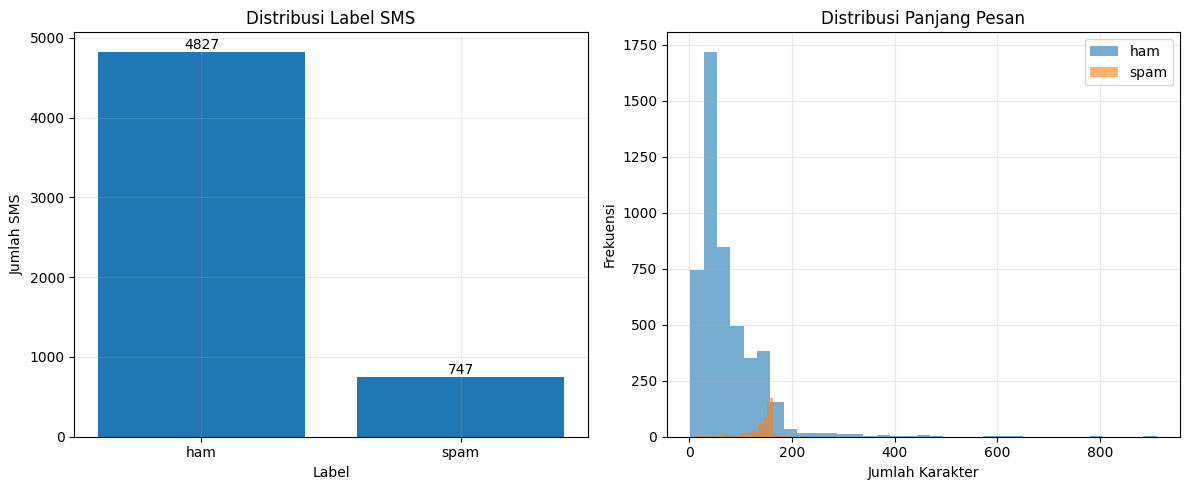

In [4]:
# Panjang pesan dan jumlah kata
df["jumlah_karakter"] = df["message"].str.len()
df["jumlah_kata"] = df["message"].str.split().str.len()

# Distribusi label
distribusi_label = df["label"].value_counts()

persentase_label = (
    df["label"].value_counts(normalize=True) * 100
)

tabel_label = pd.DataFrame({
    "Jumlah": distribusi_label,
    "Persentase (%)": persentase_label
})

print("Distribusi label:")
print(tabel_label.round(2))

# Statistik panjang SMS per label
statistik_pesan = df.groupby("label").agg(
    jumlah_sms=("message", "size"),
    rata_karakter=("jumlah_karakter", "mean"),
    median_karakter=("jumlah_karakter", "median"),
    min_karakter=("jumlah_karakter", "min"),
    max_karakter=("jumlah_karakter", "max"),
    rata_kata=("jumlah_kata", "mean")
)

print("\nStatistik pesan:")
print(statistik_pesan.round(2))

# Simpan tabel
tabel_label.to_csv(
    TABEL_DIR / "distribusi_label.csv"
)

statistik_pesan.to_csv(
    TABEL_DIR / "statistik_pesan.csv"
)

# Visualisasi distribusi label
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    distribusi_label.index,
    distribusi_label.values
)

axes[0].set_title("Distribusi Label SMS")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Jumlah SMS")

for i, nilai in enumerate(distribusi_label.values):
    axes[0].text(
        i, nilai, str(nilai),
        ha="center", va="bottom"
    )

# Histogram panjang SMS
for label in ["ham", "spam"]:
    subset = df[df["label"] == label]

    axes[1].hist(
        subset["jumlah_karakter"],
        bins=35,
        alpha=0.6,
        label=label
    )

axes[1].set_title("Distribusi Panjang Pesan")
axes[1].set_xlabel("Jumlah Karakter")
axes[1].set_ylabel("Frekuensi")
axes[1].legend()

plt.tight_layout()
simpan_gambar("distribusi_dataset")

In [5]:
def preprocess_text(text):
    text = str(text)

    # Lowercase
    text = text.lower()

    # Normalisasi whitespace
    text = re.sub(r"\s+", " ", text)

    # Menghapus spasi di awal dan akhir
    text = text.strip()

    return text

df["clean_text"] = df["message"].apply(preprocess_text)

print("Contoh sebelum dan sesudah preprocessing:")

print(
    df[["sample_id", "message", "clean_text"]]
    .head(10)
    .to_string(index=False)
)

print("\nJumlah pesan kosong setelah preprocessing:")
print((df["clean_text"] == "").sum())

# Periksa seluruh teks sebelum ekstraksi fitur
assert (df["clean_text"] != "").all()

# Simpan dataset hasil preprocessing
df.to_csv(
    DATA_DIR / "sms_preprocessed.csv",
    index=False
)

Contoh sebelum dan sesudah preprocessing:
 sample_id                                                                                                                                                          message                                                                                                                                                       clean_text
         1                                                  Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...                                                  go until jurong point, crazy.. available only in bugis n great world la e buffet... cine there got amore wat...
         2                                                                                                                                    Ok lar... Joking wif u oni...                                                                                                                         

In [6]:
tfidf = TfidfVectorizer(
    lowercase=False,
    stop_words="english",
    max_df=0.95,
    min_df=2,
    ngram_range=(1, 2),
    sublinear_tf=True,
    norm="l2"
)

# Mengubah teks ke matriks TF-IDF
X_tfidf = tfidf.fit_transform(df["clean_text"])

feature_names = tfidf.get_feature_names_out()

print("Ukuran matriks TF-IDF:", X_tfidf.shape)
print("Jumlah dokumen:", X_tfidf.shape[0])
print("Jumlah fitur:", X_tfidf.shape[1])

print("\nContoh 20 fitur pertama:")
print(feature_names[:20])

print("\nJumlah nilai bukan nol:")
print(X_tfidf.nnz)

print("\nSparsity (%):")
sparsity = (
    1 - X_tfidf.nnz /
    (X_tfidf.shape[0] * X_tfidf.shape[1])
) * 100

print(round(sparsity, 2))

Ukuran matriks TF-IDF: (5574, 9207)
Jumlah dokumen: 5574
Jumlah fitur: 9207

Contoh 20 fitur pertama:
['00' '00 sub' '00 subs' '000' '000 bonus' '000 cash' '000 homeowners'
 '000 pounds' '000 prize' '000 xmas' '008704050406' '008704050406 sp'
 '01223585334' '01223585334 cum' '02' '02 06' '02 09' '0207' '0207 153'
 '02073162414']

Jumlah nilai bukan nol:
55367

Sparsity (%):
99.89


Bentuk TF-IDF: (5574, 9207)
Bentuk setelah SVD: (5574, 100)
Bentuk input K-Means: (5574, 100)
Total explained variance SVD: 21.18 %


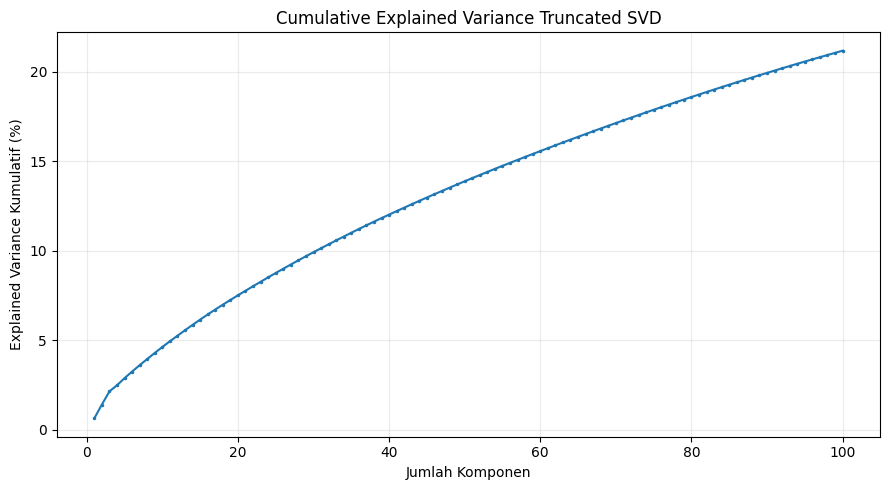

In [7]:
# Menyesuaikan jumlah komponen dengan jumlah fitur
n_components = min(
    N_COMPONENTS,
    X_tfidf.shape[1] - 1
)

assert n_components >= 2, (
    "Jumlah fitur TF-IDF tidak cukup untuk SVD."
)

svd = TruncatedSVD(
    n_components=n_components,
    random_state=RANDOM_STATE
)

# Reduksi dimensi
X_svd = svd.fit_transform(X_tfidf)

# Normalisasi panjang vektor
normalizer = Normalizer(norm="l2")

X_model = normalizer.fit_transform(X_svd)

# Persentase variansi yang dipertahankan SVD
explained_variance = (
    svd.explained_variance_ratio_.sum() * 100
)

print("Bentuk TF-IDF:", X_tfidf.shape)
print("Bentuk setelah SVD:", X_svd.shape)
print("Bentuk input K-Means:", X_model.shape)

print(
    "Total explained variance SVD:",
    round(explained_variance, 2), "%"
)

# Visualisasi variansi kumulatif
cumulative_variance = np.cumsum(
    svd.explained_variance_ratio_
) * 100

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker=".",
    markersize=3
)

plt.title("Cumulative Explained Variance Truncated SVD")
plt.xlabel("Jumlah Komponen")
plt.ylabel("Explained Variance Kumulatif (%)")

plt.tight_layout()
simpan_gambar("svd_explained_variance")

In [8]:
# Menggunakan sampel tetap untuk evaluasi silhouette.
# Pemilihan k tidak menggunakan label ham/spam.

rng = np.random.default_rng(RANDOM_STATE)

sample_size = min(
    SILHOUETTE_SAMPLE_SIZE,
    len(df)
)

sample_idx = np.sort(
    rng.choice(
        len(df),
        size=sample_size,
        replace=False
    )
)

results = []
models = {}

for k in K_RANGE:
    print(f"Melatih K-Means dengan k={k}")

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=N_INIT,
        max_iter=300,
        tol=1e-4,
        algorithm="lloyd",
        random_state=RANDOM_STATE
    )

    labels = model.fit_predict(X_model)

    models[k] = model

    # Evaluasi internal
    silhouette = silhouette_score(
        X_model[sample_idx],
        labels[sample_idx],
        metric="euclidean"
    )

    dbi = davies_bouldin_score(
        X_model,
        labels
    )

    ch = calinski_harabasz_score(
        X_model,
        labels
    )

    results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette,
        "DBI": dbi,
        "CH": ch,
        "Iterasi": model.n_iter_
    })

results_df = pd.DataFrame(results)

print("\nTabel evaluasi kandidat k:")
print(results_df.round(4).to_string(index=False))

# Simpan hasil eksperimen
results_df.to_csv(
    TABEL_DIR / "evaluasi_k.csv",
    index=False
)

Melatih K-Means dengan k=2
Melatih K-Means dengan k=3
Melatih K-Means dengan k=4
Melatih K-Means dengan k=5
Melatih K-Means dengan k=6
Melatih K-Means dengan k=7
Melatih K-Means dengan k=8

Tabel evaluasi kandidat k:
 k   Inertia  Silhouette    DBI       CH  Iterasi
 2 5248.3144      0.0204 5.1695 111.5349       15
 3 5121.6282      0.0315 3.8090 126.0375       48
 4 5030.7816      0.0369 3.5375 119.0550       27
 5 4967.7662      0.0397 4.0180 108.0681       13
 6 4896.9027      0.0437 3.5487 103.8048       24
 7 4836.0842      0.0494 4.2378  99.2446       38
 8 4782.5906      0.0487 3.4794  94.8965       29


Jumlah cluster terpilih: 7

Evaluasi model terpilih:
k                7.0000
Inertia       4836.0842
Silhouette       0.0494
DBI              4.2378
CH              99.2446
Iterasi         38.0000
Name: 5, dtype: float64


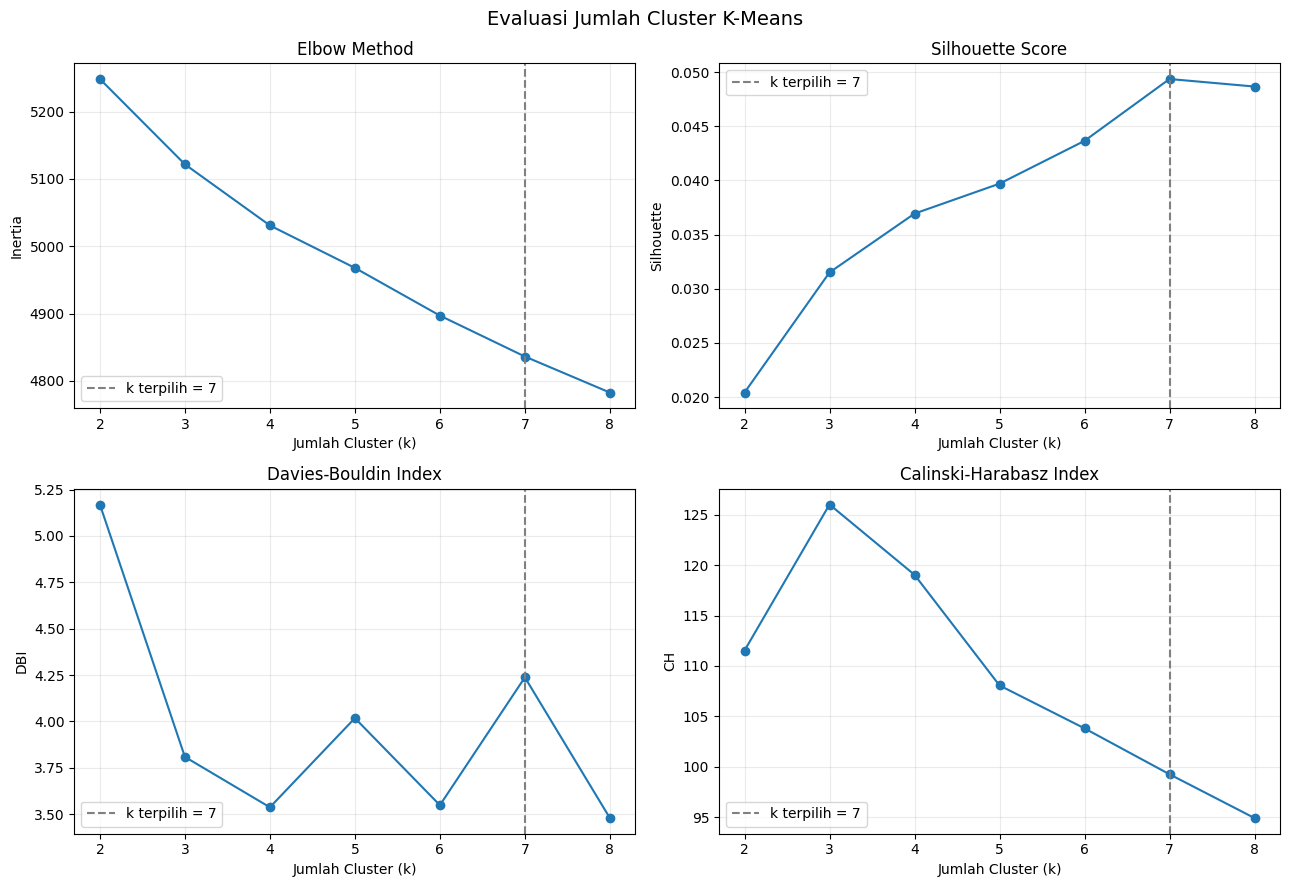

In [9]:
# Pemilihan berdasarkan silhouette tertinggi
best_idx = results_df["Silhouette"].idxmax()

best_k = int(
    results_df.loc[best_idx, "k"]
)

print("Jumlah cluster terpilih:", best_k)

print("\nEvaluasi model terpilih:")
print(results_df.loc[best_idx].round(4))

# Visualisasi seluruh metrik
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metrics = [
    ("Inertia", "Elbow Method", "Inertia"),
    ("Silhouette", "Silhouette Score", "Silhouette"),
    ("DBI", "Davies-Bouldin Index", "DBI"),
    ("CH", "Calinski-Harabasz Index", "CH")
]

for ax, (column, title, ylabel) in zip(
    axes.ravel(), metrics
):
    ax.plot(
        results_df["k"],
        results_df[column],
        marker="o"
    )

    ax.axvline(
        best_k,
        linestyle="--",
        color="gray",
        label=f"k terpilih = {best_k}"
    )

    ax.set_title(title)
    ax.set_xlabel("Jumlah Cluster (k)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(list(K_RANGE))
    ax.legend()

plt.suptitle(
    "Evaluasi Jumlah Cluster K-Means",
    fontsize=14
)

plt.tight_layout()
simpan_gambar("evaluasi_jumlah_cluster")

Jumlah anggota setiap cluster:
         Jumlah SMS  Proporsi (%)
Cluster                          
0              2866         51.42
1               649         11.64
2               661         11.86
3               239          4.29
4               237          4.25
5               615         11.03
6               307          5.51

Jumlah iterasi model final:
38

Inertia model final:
4836.084162519751


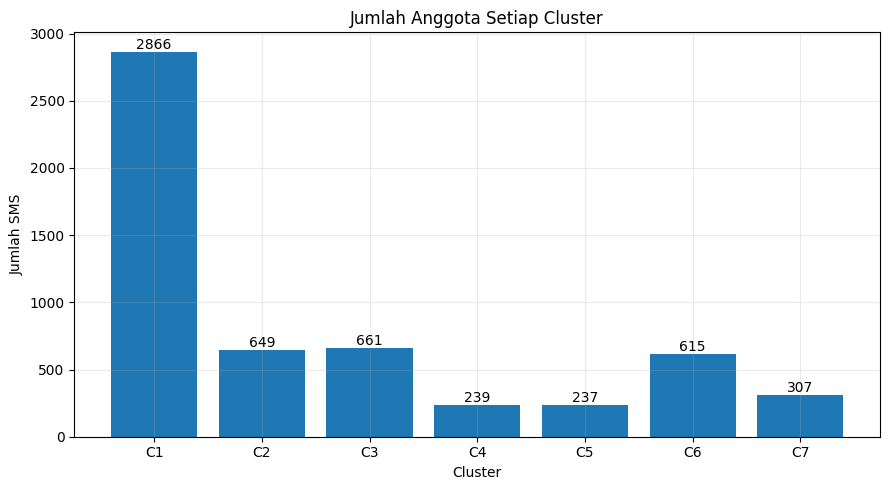

In [10]:
# Mengambil model yang telah dilatih
best_model = models[best_k]

# Mengambil keanggotaan cluster
cluster_labels = best_model.labels_

# Menyimpan hasil ke DataFrame
df["cluster"] = cluster_labels

# Mengurutkan cluster
cluster_ids = sorted(df["cluster"].unique())

# Statistik jumlah anggota
jumlah_cluster = (
    df["cluster"]
    .value_counts()
    .sort_index()
)

proporsi_cluster = (
    df["cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

tabel_cluster = pd.DataFrame({
    "Jumlah SMS": jumlah_cluster,
    "Proporsi (%)": proporsi_cluster
})

tabel_cluster.index.name = "Cluster"

print("Jumlah anggota setiap cluster:")
print(tabel_cluster.round(2))

print("\nJumlah iterasi model final:")
print(best_model.n_iter_)

print("\nInertia model final:")
print(best_model.inertia_)

tabel_cluster.to_csv(
    TABEL_DIR / "ukuran_cluster.csv"
)

# Grafik jumlah anggota cluster
plt.figure(figsize=(9, 5))

bars = plt.bar(
    [f"C{i+1}" for i in cluster_ids],
    jumlah_cluster.values
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.title("Jumlah Anggota Setiap Cluster")
plt.xlabel("Cluster")
plt.ylabel("Jumlah SMS")

plt.tight_layout()
simpan_gambar("jumlah_anggota_cluster")

Silhouette per cluster:
         jumlah_sampel  silhouette_rata_rata  silhouette_minimum  silhouette_maksimum  jumlah_negatif
cluster                                                                                              
0                  608               -0.0032             -0.1358               0.0227             302
1                  146                0.0718             -0.0494               0.1606               3
2                  153                0.0436             -0.0669               0.1200              11
3                   52                0.3708              0.1498               0.5510               0
4                   51                0.2150              0.0913               0.4222               0
5                  126                0.0468             -0.0065               0.1163               1
6                   64                0.1236             -0.0341               0.3023               2

Silhouette rata-rata:
0.0494

Jumlah sampel dengan silhou

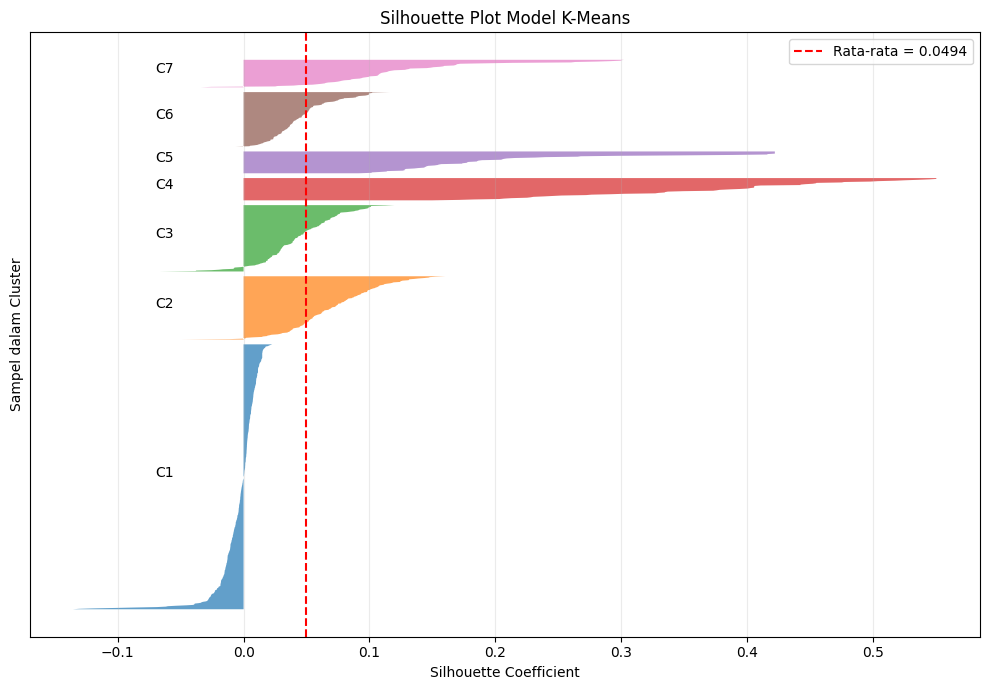

In [11]:
# Menghitung silhouette setiap sampel evaluasi
X_eval = X_model[sample_idx]
labels_eval = cluster_labels[sample_idx]

sample_silhouette_values = silhouette_samples(
    X_eval,
    labels_eval,
    metric="euclidean"
)

# Silhouette keseluruhan pada sampel evaluasi
silhouette_avg = sample_silhouette_values.mean()

# Menyimpan skor per sampel evaluasi
df_silhouette = pd.DataFrame({
    "sample_id": df.iloc[sample_idx]["sample_id"].values,
    "cluster": labels_eval,
    "silhouette": sample_silhouette_values
})

# Statistik per cluster
silhouette_cluster = df_silhouette.groupby("cluster").agg(
    jumlah_sampel=("silhouette", "size"),
    silhouette_rata_rata=("silhouette", "mean"),
    silhouette_minimum=("silhouette", "min"),
    silhouette_maksimum=("silhouette", "max"),
    jumlah_negatif=(
        "silhouette",
        lambda x: (x < 0).sum()
    )
)

print("Silhouette per cluster:")
print(silhouette_cluster.round(4))

print("\nSilhouette rata-rata:")
print(round(silhouette_avg, 4))

print("\nJumlah sampel dengan silhouette negatif:")
print((sample_silhouette_values < 0).sum())

silhouette_cluster.to_csv(
    TABEL_DIR / "silhouette_per_cluster.csv"
)

df_silhouette.to_csv(
    TABEL_DIR / "silhouette_per_sampel.csv",
    index=False
)

# Silhouette plot
fig, ax = plt.subplots(figsize=(10, 7))

y_lower = 10

for i in cluster_ids:
    values = sample_silhouette_values[
        labels_eval == i
    ]

    values.sort()

    size_cluster = len(values)
    y_upper = y_lower + size_cluster

    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        values,
        alpha=0.7
    )

    ax.text(
        -0.07,
        y_lower + 0.5 * size_cluster,
        f"C{i+1}"
    )

    y_lower = y_upper + 10

ax.axvline(
    silhouette_avg,
    color="red",
    linestyle="--",
    label=f"Rata-rata = {silhouette_avg:.4f}"
)

ax.set_title("Silhouette Plot Model K-Means")
ax.set_xlabel("Silhouette Coefficient")
ax.set_ylabel("Sampel dalam Cluster")
ax.set_yticks([])
ax.legend()

plt.tight_layout()
simpan_gambar("silhouette_plot")

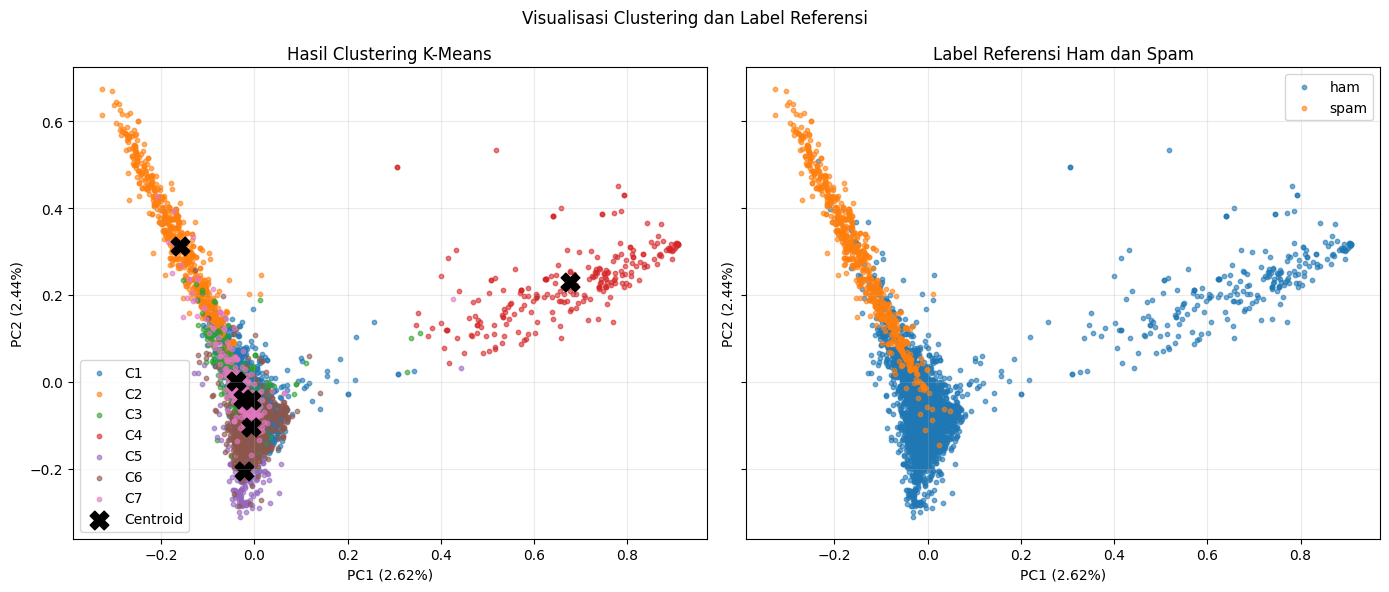

Total explained variance PCA 2D: 5.06 %


In [12]:
# PCA hanya digunakan untuk visualisasi.
# Model K-Means tetap dilatih pada X_model.

pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_2d = pca.fit_transform(X_model)

# Memproyeksikan centroid ke bidang PCA yang sama
centers_2d = pca.transform(
    best_model.cluster_centers_
)

variance_ratio = (
    pca.explained_variance_ratio_ * 100
)

# Data koordinat visualisasi
df_pca = pd.DataFrame({
    "sample_id": df["sample_id"],
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1],
    "cluster": df["cluster"],
    "label": df["label"]
})

df_pca.to_csv(
    TABEL_DIR / "koordinat_pca.csv",
    index=False
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    sharex=True,
    sharey=True
)

# Panel 1: Hasil K-Means
for i in cluster_ids:
    mask = df["cluster"].values == i

    axes[0].scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        s=10,
        alpha=0.6,
        label=f"C{i+1}"
    )

axes[0].scatter(
    centers_2d[:, 0],
    centers_2d[:, 1],
    marker="X",
    s=180,
    c="black",
    label="Centroid"
)

axes[0].set_title("Hasil Clustering K-Means")
axes[0].legend()

# Panel 2: Label referensi
for label in ["ham", "spam"]:
    mask = df["label"].values == label

    axes[1].scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        s=10,
        alpha=0.6,
        label=label
    )

axes[1].set_title("Label Referensi Ham dan Spam")
axes[1].legend()

for ax in axes:
    ax.set_xlabel(
        f"PC1 ({variance_ratio[0]:.2f}%)"
    )
    ax.set_ylabel(
        f"PC2 ({variance_ratio[1]:.2f}%)"
    )

plt.suptitle(
    "Visualisasi Clustering dan Label Referensi"
)

plt.tight_layout()
simpan_gambar("visualisasi_cluster_pca")

print(
    "Total explained variance PCA 2D:",
    round(variance_ratio.sum(), 2), "%"
)

In [13]:
TOP_N_WORDS = 15

top_words_results = []

# Rata-rata bobot TF-IDF per cluster
mean_tfidf_per_cluster = []

for cluster_id in cluster_ids:
    mask = df["cluster"].values == cluster_id

    mean_tfidf = np.asarray(
        X_tfidf[mask].mean(axis=0)
    ).ravel()

    mean_tfidf_per_cluster.append(mean_tfidf)

    top_indices = np.argsort(
        mean_tfidf
    )[-TOP_N_WORDS:][::-1]

    print(f"\nCluster C{cluster_id+1}")
    print("-" * 40)

    for rank, idx in enumerate(
        top_indices, start=1
    ):
        word = feature_names[idx]
        weight = mean_tfidf[idx]

        print(f"{rank:2d}. {word:<25} {weight:.5f}")

        top_words_results.append({
            "Cluster": f"C{cluster_id+1}",
            "Rank": rank,
            "Kata": word,
            "Mean_TFIDF": weight
        })

df_top_words = pd.DataFrame(
    top_words_results
)

df_top_words.to_csv(
    TABEL_DIR / "kata_dominan_cluster.csv",
    index=False
)


Cluster C1
----------------------------------------
 1. ll                        0.01643
 2. know                      0.01468
 3. come                      0.01466
 4. sorry                     0.01319
 5. want                      0.01235
 6. going                     0.01221
 7. later                     0.01195
 8. home                      0.01173
 9. time                      0.01115
10. da                        0.01069
11. need                      0.00955
12. don                       0.00909
13. did                       0.00883
14. oh                        0.00851
15. pls                       0.00846

Cluster C2
----------------------------------------
 1. free                      0.05214
 2. txt                       0.02752
 3. mobile                    0.02443
 4. stop                      0.02421
 5. text                      0.02374
 6. reply                     0.02306
 7. claim                     0.02086
 8. www                       0.02082
 9. prize           

Profil karakteristik setiap cluster:
         jumlah_sms  rata_karakter  rata_kata  persentase_angka  persentase_url  persentase_seru
cluster                                                                                         
0              2866          64.63      12.86             15.42            0.07            11.97
1               649         132.42      22.87             86.90           15.87            44.99
2               661          98.92      19.27             17.10            0.00            23.00
3               239         108.77      19.72             17.99            0.84             5.02
4               237          50.23      10.96             18.57            0.00             6.33
5               615          70.95      14.90             31.06            0.16             7.64
6               307          99.30      19.54             21.82            0.00            21.82


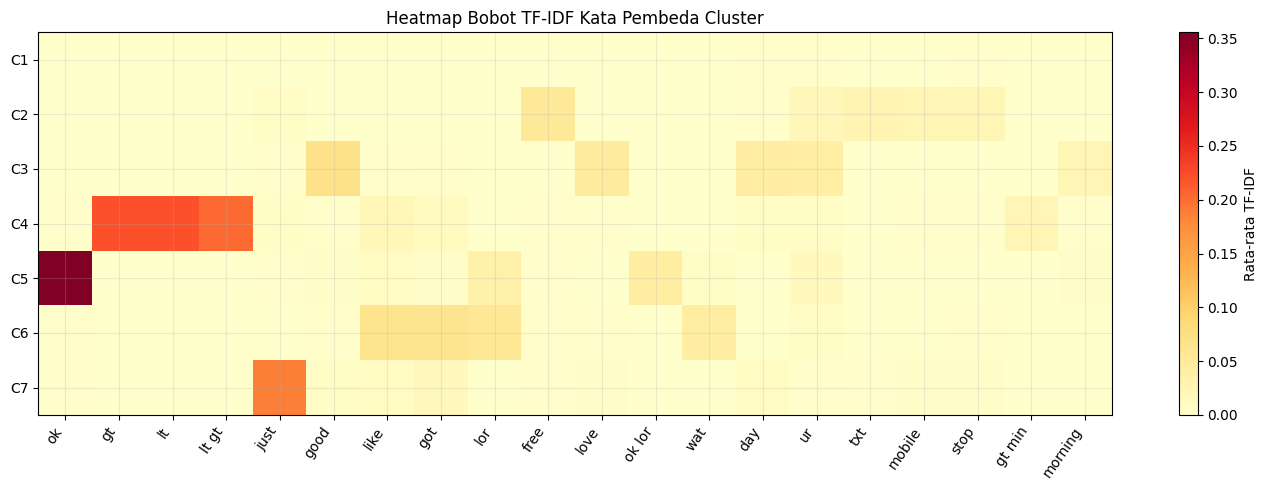

In [14]:
# Membuat fitur deskriptif tambahan
# Fitur ini TIDAK digunakan untuk melatih K-Means.

df["mengandung_angka"] = (
    df["message"].str.contains(r"\d", regex=True)
)

df["mengandung_url"] = (
    df["message"].str.contains(
        r"https?://|www\.",
        case=False,
        regex=True
    )
)

df["mengandung_seru"] = (
    df["message"].str.contains(
        "!",
        regex=False
    )
)

profil_cluster = df.groupby("cluster").agg(
    jumlah_sms=("message", "size"),
    rata_karakter=("jumlah_karakter", "mean"),
    rata_kata=("jumlah_kata", "mean"),
    persentase_angka=("mengandung_angka", "mean"),
    persentase_url=("mengandung_url", "mean"),
    persentase_seru=("mengandung_seru", "mean")
)

# Mengubah proporsi menjadi persen
percentage_columns = [
    "persentase_angka",
    "persentase_url",
    "persentase_seru"
]

profil_cluster[percentage_columns] *= 100

print("Profil karakteristik setiap cluster:")
print(profil_cluster.round(2))

profil_cluster.to_csv(
    TABEL_DIR / "profil_cluster.csv"
)

# Heatmap kata/frasa yang paling berbeda
# antarcluster menurut rata-rata TF-IDF

mean_matrix = np.vstack(
    mean_tfidf_per_cluster
)

# Selisih bobot tertinggi dan terendah antarkelompok
term_difference = (
    mean_matrix.max(axis=0)
    - mean_matrix.min(axis=0)
)

top_discriminative_idx = np.argsort(
    term_difference
)[-20:][::-1]

heatmap_data = mean_matrix[
    :, top_discriminative_idx
]

heatmap_words = feature_names[
    top_discriminative_idx
]

fig, ax = plt.subplots(figsize=(14, 5))

im = ax.imshow(
    heatmap_data,
    aspect="auto",
    cmap="YlOrRd"
)

ax.set_xticks(
    range(len(heatmap_words))
)

ax.set_xticklabels(
    heatmap_words,
    rotation=55,
    ha="right"
)

ax.set_yticks(
    range(len(cluster_ids))
)

ax.set_yticklabels(
    [f"C{i+1}" for i in cluster_ids]
)

ax.set_title(
    "Heatmap Bobot TF-IDF Kata Pembeda Cluster"
)

plt.colorbar(
    im,
    ax=ax,
    label="Rata-rata TF-IDF"
)

plt.tight_layout()
simpan_gambar("heatmap_kata_cluster")

Adjusted Rand Index: 0.1609
Normalized Mutual Information: 0.2411

Tabulasi Cluster vs Label:
label     ham  spam   All
cluster                  
0        2755   111  2866
1          71   578   649
2         652     9   661
3         239     0   239
4         236     1   237
5         606     9   615
6         268    39   307
All      4827   747  5574

Persentase Label per Cluster:
label       ham   spam
cluster               
0         96.13   3.87
1         10.94  89.06
2         98.64   1.36
3        100.00   0.00
4         99.58   0.42
5         98.54   1.46
6         87.30  12.70


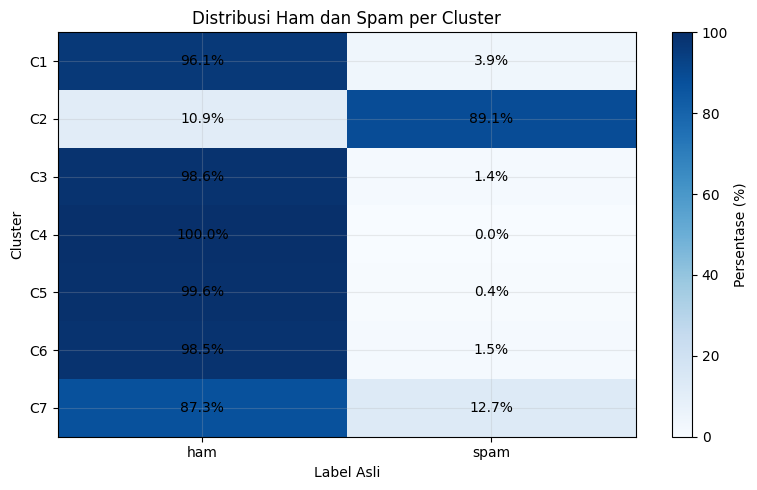

In [15]:
# Evaluasi eksternal
ari = adjusted_rand_score(
    df["label"],
    df["cluster"]
)

nmi = normalized_mutual_info_score(
    df["label"],
    df["cluster"]
)

print("Adjusted Rand Index:", round(ari, 4))
print("Normalized Mutual Information:", round(nmi, 4))

# Tabulasi jumlah SMS
tabulasi = pd.crosstab(
    df["cluster"],
    df["label"],
    margins=True
)

print("\nTabulasi Cluster vs Label:")
print(tabulasi)

# Persentase label dalam setiap cluster
tabulasi_persen = pd.crosstab(
    df["cluster"],
    df["label"],
    normalize="index"
) * 100

print("\nPersentase Label per Cluster:")
print(tabulasi_persen.round(2))

# Simpan hasil
tabulasi.to_csv(
    TABEL_DIR / "tabulasi_cluster_label.csv"
)

tabulasi_persen.to_csv(
    TABEL_DIR / "persentase_cluster_label.csv"
)

evaluasi_eksternal = pd.DataFrame({
    "Metrik": ["ARI", "NMI"],
    "Nilai": [ari, nmi]
})

evaluasi_eksternal.to_csv(
    TABEL_DIR / "evaluasi_eksternal.csv",
    index=False
)

# Heatmap distribusi label
fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(
    tabulasi_persen.values,
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=100
)

ax.set_xticks(
    range(len(tabulasi_persen.columns))
)

ax.set_xticklabels(
    tabulasi_persen.columns
)

ax.set_yticks(
    range(len(tabulasi_persen.index))
)

ax.set_yticklabels([
    f"C{i+1}" for i in tabulasi_persen.index
])

# Menampilkan nilai persentase pada heatmap
for i in range(tabulasi_persen.shape[0]):
    for j in range(tabulasi_persen.shape[1]):
        value = tabulasi_persen.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.1f}%",
            ha="center",
            va="center"
        )

ax.set_title("Distribusi Ham dan Spam per Cluster")
ax.set_xlabel("Label Asli")
ax.set_ylabel("Cluster")

plt.colorbar(
    im,
    ax=ax,
    label="Persentase (%)"
)

plt.tight_layout()
simpan_gambar("heatmap_cluster_label")

In [16]:
# Pesan representatif dipilih berdasarkan kedekatan
# terhadap centroid pada ruang X_model.

distances = best_model.transform(X_model)

def samarkan_pesan(text):
    text = str(text)

    # Menyamarkan URL
    text = re.sub(
        r"https?://\S+|www\.\S+",
        "[URL]",
        text,
        flags=re.IGNORECASE
    )

    # Menyamarkan email
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.\w+\b",
        "[EMAIL]",
        text
    )

    # Menyamarkan rangkaian nomor panjang
    text = re.sub(
        r"\+?\d[\d\s().-]{6,}\d",
        "[NUMBER]",
        text
    )

    return text[:160]

representative_messages = []

for cluster_id in cluster_ids:
    print(f"\nCluster C{cluster_id+1}")
    print("=" * 60)

    # Hanya pesan dalam cluster terkait
    member_idx = np.where(
        cluster_labels == cluster_id
    )[0]

    # Urutkan dari centroid terdekat
    sorted_idx = member_idx[
        np.argsort(
            distances[member_idx, cluster_id]
        )
    ]

    selected_idx = sorted_idx[:5]

    for rank, idx in enumerate(
        selected_idx, start=1
    ):
        message = samarkan_pesan(
            df.iloc[idx]["message"]
        )

        print(f"{rank}. {message}")

        representative_messages.append({
            "Cluster": f"C{cluster_id+1}",
            "Sample_ID": int(
                df.iloc[idx]["sample_id"]
            ),
            "Jarak_Centroid": float(
                distances[idx, cluster_id]
            ),
            "Pesan": message
        })

df_representative = pd.DataFrame(
    representative_messages
)

df_representative.to_csv(
    TABEL_DIR / "pesan_representatif.csv",
    index=False
)

# Periksa kembali pesan secara manual sebelum
# memasukkannya dalam laporan publik.


Cluster C1
1. What about this one then.
2. Ultimately tor motive tui achieve korli.
3. That's my honeymoon outfit. :)
4. U too...
5. 645

Cluster C2
1. Latest Nokia Mobile or iPOD MP3 Player +£400 proze GUARANTEED! Reply with: WIN to 83355 now! Norcorp Ltd.£1,50/Mtmsgrcvd18+
2. Our records indicate u maybe entitled to 5000 pounds in compensation for the Accident you had. To claim 4 free reply with CLAIM to this msg. 2 stop txt STOP
3. Ur ringtone service has changed! 25 Free credits! Go to club4mobiles.com to choose content now! Stop? txt CLUB STOP to [NUMBER]p/wk Club4 PO Box1146 MK45 2WT
4. u r subscribed 2 TEXTCOMP 250 wkly comp. 1st wk?s free question follows, subsequent wks charged@150p/msg.2 unsubscribe txt STOP 2 84128,custcare [NUMBER]
5. SplashMobile: Choose from 1000s of gr8 tones each wk! This is a subscrition service with weekly tones costing 300p. U have one credit - kick back and ENJOY

Cluster C3
1. Never blame a day in ur life. Good days give u happiness. Bad days give

Perbandingan metode:
                                Metode  Silhouette_Cosine_TFIDF  ARI_Label  NMI_Label
0                     TF-IDF + K-Means                   0.0094    -0.1079     0.0331
1  TF-IDF + SVD + Normalizer + K-Means                   0.0154     0.1609     0.2411

ARI antara kedua hasil clustering:
0.025


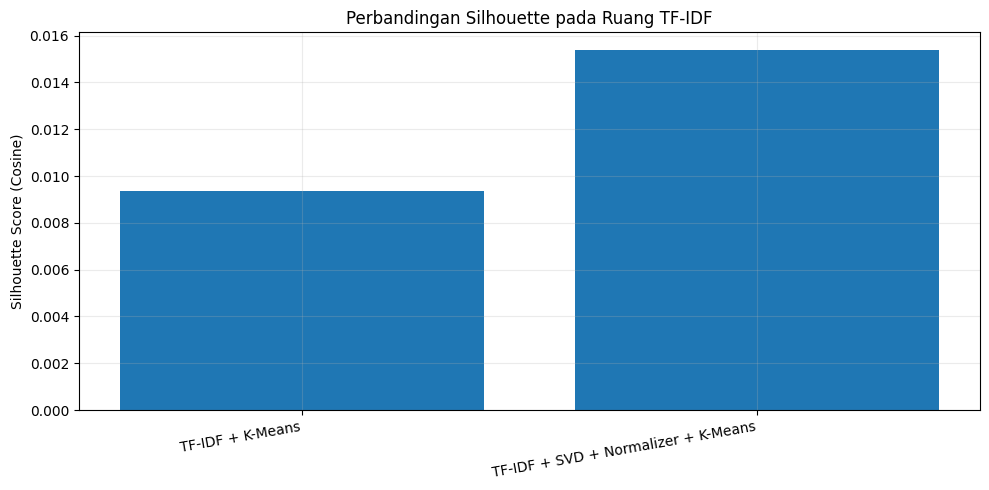

In [17]:
# Eksperimen baseline: K-Means langsung pada TF-IDF
baseline_model = KMeans(
    n_clusters=best_k,
    init="k-means++",
    n_init=N_INIT,
    random_state=RANDOM_STATE
)

baseline_labels = baseline_model.fit_predict(
    X_tfidf
)

# Silhouette pada ruang evaluasi yang sama
baseline_silhouette = silhouette_score(
    X_tfidf[sample_idx],
    baseline_labels[sample_idx],
    metric="cosine"
)

svd_silhouette_common = silhouette_score(
    X_tfidf[sample_idx],
    cluster_labels[sample_idx],
    metric="cosine"
)

# Evaluasi eksternal setelah model ditetapkan
baseline_ari = adjusted_rand_score(
    df["label"],
    baseline_labels
)

baseline_nmi = normalized_mutual_info_score(
    df["label"],
    baseline_labels
)

# Perbandingan kesamaan partisi kedua pendekatan
ari_antar_model = adjusted_rand_score(
    baseline_labels,
    cluster_labels
)

perbandingan_model = pd.DataFrame({
    "Metode": [
        "TF-IDF + K-Means",
        "TF-IDF + SVD + Normalizer + K-Means"
    ],
    "Silhouette_Cosine_TFIDF": [
        baseline_silhouette,
        svd_silhouette_common
    ],
    "ARI_Label": [
        baseline_ari,
        ari
    ],
    "NMI_Label": [
        baseline_nmi,
        nmi
    ]
})

print("Perbandingan metode:")
print(perbandingan_model.round(4))

print("\nARI antara kedua hasil clustering:")
print(round(ari_antar_model, 4))

perbandingan_model.to_csv(
    TABEL_DIR / "perbandingan_model.csv",
    index=False
)

# Visualisasi perbandingan silhouette
plt.figure(figsize=(10, 5))

plt.bar(
    perbandingan_model["Metode"],
    perbandingan_model["Silhouette_Cosine_TFIDF"]
)

plt.title(
    "Perbandingan Silhouette pada Ruang TF-IDF"
)

plt.ylabel("Silhouette Score (Cosine)")
plt.xticks(rotation=10, ha="right")

plt.tight_layout()
simpan_gambar("perbandingan_representasi")

Seed 0 selesai
Seed 1 selesai
Seed 2 selesai
Seed 3 selesai
Seed 4 selesai
Seed 5 selesai
Seed 6 selesai
Seed 7 selesai
Seed 8 selesai
Seed 9 selesai
Seed 10 selesai
Seed 11 selesai
Seed 12 selesai
Seed 13 selesai
Seed 14 selesai
Seed 15 selesai
Seed 16 selesai
Seed 17 selesai
Seed 18 selesai
Seed 19 selesai
Seed 20 selesai
Seed 21 selesai
Seed 22 selesai
Seed 23 selesai
Seed 24 selesai
Seed 25 selesai
Seed 26 selesai
Seed 27 selesai
Seed 28 selesai
Seed 29 selesai

Ringkasan kestabilan seed:
             Metrik      Nilai
        Jumlah Seed  30.000000
    Jumlah Pasangan 435.000000
        ARI Minimum   0.228544
      ARI Rata-rata   0.578751
       ARI Maksimum   0.962543
ARI Standar Deviasi   0.136560


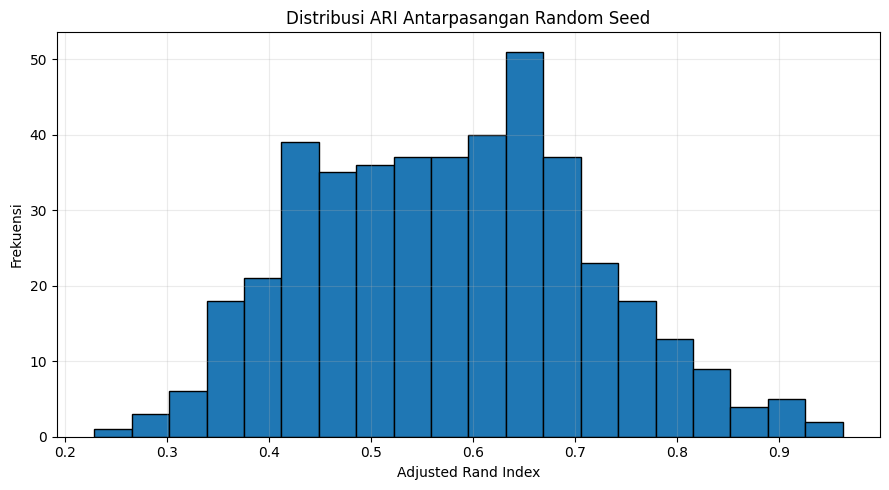

In [18]:
# Model dijalankan berulang pada representasi
# dan jumlah cluster yang sama.

seed_results = {}

for seed in range(N_STABILITY_SEEDS):
    model_seed = KMeans(
        n_clusters=best_k,
        init="k-means++",
        n_init=N_INIT,
        max_iter=300,
        tol=1e-4,
        algorithm="lloyd",
        random_state=seed
    )

    labels_seed = model_seed.fit_predict(X_model)

    seed_results[seed] = labels_seed

    print(f"Seed {seed} selesai")

# Menghitung ARI setiap pasangan seed
pairwise_ari = []

for seed_a, seed_b in itertools.combinations(
    seed_results.keys(), 2
):
    score = adjusted_rand_score(
        seed_results[seed_a],
        seed_results[seed_b]
    )

    pairwise_ari.append({
        "seed_a": seed_a,
        "seed_b": seed_b,
        "ARI": score
    })

df_stability = pd.DataFrame(pairwise_ari)

# Ringkasan kestabilan
stability_summary = pd.DataFrame({
    "Metrik": [
        "Jumlah Seed",
        "Jumlah Pasangan",
        "ARI Minimum",
        "ARI Rata-rata",
        "ARI Maksimum",
        "ARI Standar Deviasi"
    ],
    "Nilai": [
        N_STABILITY_SEEDS,
        len(df_stability),
        df_stability["ARI"].min(),
        df_stability["ARI"].mean(),
        df_stability["ARI"].max(),
        df_stability["ARI"].std()
    ]
})

print("\nRingkasan kestabilan seed:")
print(stability_summary.to_string(index=False))

df_stability.to_csv(
    TABEL_DIR / "stabilitas_seed.csv",
    index=False
)

stability_summary.to_csv(
    TABEL_DIR / "ringkasan_stabilitas.csv",
    index=False
)

# Histogram kestabilan
plt.figure(figsize=(9, 5))

plt.hist(
    df_stability["ARI"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribusi ARI Antarpasangan Random Seed")
plt.xlabel("Adjusted Rand Index")
plt.ylabel("Frekuensi")

plt.tight_layout()
simpan_gambar("stabilitas_random_seed")

In [19]:
# =================================================
# A. Validasi inertia
# =================================================

centers = best_model.cluster_centers_
labels = best_model.labels_

# Menghitung ulang sum of squared distances
squared_distances = (
    X_model - centers[labels]
) ** 2

manual_inertia = squared_distances.sum()

print("Inertia scikit-learn:")
print(best_model.inertia_)

print("\nInertia perhitungan ulang:")
print(manual_inertia)

inertia_valid = np.isclose(
    best_model.inertia_,
    manual_inertia,
    rtol=1e-6,
    atol=1e-6
)

print("\nValidasi inertia:", inertia_valid)


# =================================================
# B. Validasi centroid
# =================================================

manual_centers = np.vstack([
    X_model[labels == i].mean(axis=0)
    for i in cluster_ids
])

centroid_difference = np.max(
    np.abs(manual_centers - centers)
)

centroid_valid = np.allclose(
    manual_centers,
    centers,
    rtol=1e-5,
    atol=1e-5
)

print("\nSelisih maksimum centroid:")
print(centroid_difference)

print("Validasi centroid:", centroid_valid)


# =================================================
# C. Validasi keanggotaan cluster
# =================================================

nearest_labels, nearest_distances = (
    pairwise_distances_argmin_min(
        X_model,
        centers,
        metric="euclidean"
    )
)

jumlah_perbedaan = np.sum(
    nearest_labels != labels
)

print("\nJumlah sampel bukan centroid terdekat:")
print(jumlah_perbedaan)


# =================================================
# D. Validasi silhouette secara manual
# Menggunakan subset evaluasi yang sama
# =================================================

distance_matrix = pairwise_distances(
    X_eval,
    metric="euclidean"
)

unique_clusters = np.unique(labels_eval)

manual_silhouette_values = []

for i in range(len(X_eval)):
    own_cluster = labels_eval[i]

    same_cluster_idx = np.where(
        labels_eval == own_cluster
    )[0]

    # Silhouette bernilai nol untuk cluster singleton
    if len(same_cluster_idx) <= 1:
        manual_silhouette_values.append(0.0)
        continue

    # Rata-rata jarak ke anggota cluster sendiri,
    # tanpa menghitung jarak ke dirinya sendiri.
    a_i = (
        distance_matrix[i, same_cluster_idx].sum()
        / (len(same_cluster_idx) - 1)
    )

    # Rata-rata jarak minimum ke cluster lain
    b_i = min(
        distance_matrix[
            i,
            labels_eval == other_cluster
        ].mean()
        for other_cluster in unique_clusters
        if other_cluster != own_cluster
    )

    denominator = max(a_i, b_i)

    if denominator > 0:
        s_i = (b_i - a_i) / denominator
    else:
        s_i = 0.0

    manual_silhouette_values.append(s_i)

manual_silhouette_values = np.array(
    manual_silhouette_values
)

manual_silhouette = (
    manual_silhouette_values.mean()
)

library_silhouette = silhouette_score(
    X_eval,
    labels_eval,
    metric="euclidean"
)

print("\nSilhouette scikit-learn:")
print(library_silhouette)

print("\nSilhouette perhitungan manual:")
print(manual_silhouette)

silhouette_valid = np.isclose(
    library_silhouette,
    manual_silhouette,
    rtol=1e-6,
    atol=1e-6
)

print("\nValidasi silhouette:", silhouette_valid)


# =================================================
# E. Ringkasan validasi
# =================================================

validasi = {
    "inertia_library": float(best_model.inertia_),
    "inertia_manual": float(manual_inertia),
    "inertia_valid": bool(inertia_valid),
    "centroid_max_difference": float(
        centroid_difference
    ),
    "centroid_valid": bool(centroid_valid),
    "jumlah_penempatan_berbeda": int(
        jumlah_perbedaan
    ),
    "silhouette_library": float(
        library_silhouette
    ),
    "silhouette_manual": float(
        manual_silhouette
    ),
    "silhouette_valid": bool(
        silhouette_valid
    )
}

with open(
    HASIL_DIR / "validasi.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        validasi,
        f,
        indent=4
    )

print("\nValidasi disimpan ke validasi.json")

Inertia scikit-learn:
4836.084162519751

Inertia perhitungan ulang:
4836.084162519767

Validasi inertia: True

Selisih maksimum centroid:
3.885780586188048e-16
Validasi centroid: True

Jumlah sampel bukan centroid terdekat:
0

Silhouette scikit-learn:
0.04936377579830728

Silhouette perhitungan manual:
0.04936377579830728

Validasi silhouette: True

Validasi disimpan ke validasi.json


In [20]:
# Menyimpan komponen model
joblib.dump(
    tfidf,
    MODEL_DIR / "tfidf_vectorizer.joblib"
)

joblib.dump(
    svd,
    MODEL_DIR / "truncated_svd.joblib"
)

joblib.dump(
    normalizer,
    MODEL_DIR / "normalizer.joblib"
)

joblib.dump(
    best_model,
    MODEL_DIR / "kmeans_final.joblib"
)

# Menyimpan keanggotaan cluster
df_keanggotaan = df[[
    "sample_id",
    "label",
    "cluster",
    "jumlah_karakter",
    "jumlah_kata"
]].copy()

df_keanggotaan["cluster_name"] = (
    df_keanggotaan["cluster"]
    .apply(lambda x: f"C{x+1}")
)

df_keanggotaan.to_csv(
    HASIL_DIR / "keanggotaan_cluster.csv",
    index=False
)

# Metadata eksperimen
metadata = {
    "dataset": {
        "nama": "SMS Spam Collection",
        "sumber": DATASET_PAGE,
        "download_url": DATASET_URL,
        "doi": "10.24432/C5CC84",
        "sha256": dataset_sha256,
        "jumlah_sms_asli": int(len(df_raw)),
        "jumlah_sms_digunakan": int(len(df))
    },

    "preprocessing": {
        "lowercase": True,
        "whitespace_normalization": True,
        "remove_digits": False,
        "remove_urls": False,
        "remove_duplicates": False
    },

    "representasi": {
        "metode": "TF-IDF + Truncated SVD + Normalizer",
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_df": 0.95,
        "stop_words": "english",
        "svd_components": int(n_components),
        "svd_explained_variance": float(
            explained_variance
        )
    },

    "model": {
        "algoritma": "K-Means",
        "k_candidates": list(K_RANGE),
        "best_k": int(best_k),
        "selection_metric": "Silhouette",
        "selection_sample_size": int(sample_size),
        "n_init": N_INIT,
        "random_state": RANDOM_STATE,
        "max_iter": 300,
        "tol": 1e-4
    },

    "hasil": {
        "inertia": float(best_model.inertia_),
        "silhouette_sample": float(
            silhouette_avg
        ),
        "dbi": float(
            results_df.loc[best_idx, "DBI"]
        ),
        "ch": float(
            results_df.loc[best_idx, "CH"]
        ),
        "ari": float(ari),
        "nmi": float(nmi),
        "iterasi": int(best_model.n_iter_)
    },

    "environment": {
        "timestamp": datetime.now().isoformat(),
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "scikit_learn": sklearn.__version__,
        "matplotlib": matplotlib.__version__
    }
}

with open(
    HASIL_DIR / "provenance.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=4
    )

# Menyimpan daftar versi pustaka
requirements = [
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"scipy=={scipy.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    f"requests=={requests.__version__}",
    f"joblib=={joblib.__version__}"
]

(ROOT / "requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("Semua model dan hasil telah disimpan.")
print("Lokasi:", ROOT.resolve())

Semua model dan hasil telah disimpan.
Lokasi: /content/sms_clustering_laporan


In [21]:
print("=" * 65)
print("RINGKASAN HASIL CLUSTERING SMS SPAM COLLECTION")
print("=" * 65)

print("\n1. DATASET")
print("Jumlah SMS:", len(df))
print("Jumlah ham:", (df["label"] == "ham").sum())
print("Jumlah spam:", (df["label"] == "spam").sum())

print("\n2. FEATURE EXTRACTION")
print("Jumlah fitur TF-IDF:", X_tfidf.shape[1])
print("Komponen SVD:", X_model.shape[1])
print(
    "Explained variance SVD:",
    f"{explained_variance:.2f}%"
)

print("\n3. MODEL K-MEANS")
print("Jumlah cluster terpilih:", best_k)
print("Inertia:", round(best_model.inertia_, 4))
print("Silhouette:", round(silhouette_avg, 4))
print(
    "Davies-Bouldin:",
    round(results_df.loc[best_idx, "DBI"], 4)
)
print(
    "Calinski-Harabasz:",
    round(results_df.loc[best_idx, "CH"], 4)
)

print("\n4. UKURAN CLUSTER")
print(tabel_cluster.round(2))

print("\n5. EVALUASI EKSTERNAL")
print("ARI:", round(ari, 4))
print("NMI:", round(nmi, 4))

print("\n6. TABULASI CLUSTER DAN LABEL")
print(tabulasi)

print("\n7. KESTABILAN MODEL")
print(
    "ARI rata-rata antar-seed:",
    round(df_stability["ARI"].mean(), 4)
)
print(
    "ARI minimum antar-seed:",
    round(df_stability["ARI"].min(), 4)
)

print("\n8. VALIDASI")
print("Inertia valid:", inertia_valid)
print("Centroid valid:", centroid_valid)
print("Silhouette valid:", silhouette_valid)

print("\n9. OUTPUT FILE")
print("\nTabel:")
for path in sorted(TABEL_DIR.glob("*.csv")):
    print("-", path.name)

print("\nGambar:")
for path in sorted(GAMBAR_DIR.glob("*.png")):
    print("-", path.name)

print("\n" + "=" * 65)
print("EKSPERIMEN SELESAI")
print("=" * 65)

RINGKASAN HASIL CLUSTERING SMS SPAM COLLECTION

1. DATASET
Jumlah SMS: 5574
Jumlah ham: 4827
Jumlah spam: 747

2. FEATURE EXTRACTION
Jumlah fitur TF-IDF: 9207
Komponen SVD: 100
Explained variance SVD: 21.18%

3. MODEL K-MEANS
Jumlah cluster terpilih: 7
Inertia: 4836.0842
Silhouette: 0.0494
Davies-Bouldin: 4.2378
Calinski-Harabasz: 99.2446

4. UKURAN CLUSTER
         Jumlah SMS  Proporsi (%)
Cluster                          
0              2866         51.42
1               649         11.64
2               661         11.86
3               239          4.29
4               237          4.25
5               615         11.03
6               307          5.51

5. EVALUASI EKSTERNAL
ARI: 0.1609
NMI: 0.2411

6. TABULASI CLUSTER DAN LABEL
label     ham  spam   All
cluster                  
0        2755   111  2866
1          71   578   649
2         652     9   661
3         239     0   239
4         236     1   237
5         606     9   615
6         268    39   307
All      4827   747  5